# Лабораторная работа №6
## «Расчёт надёжности ПО»

**Студент:** Пермяков Дмитрий Кириллович, ИУ5-22М
**Вариант:** 18

---

### Суть
Это не про железо, а про **программное обеспечение**. У ПО другая надёжность: отказ = найденная ошибка. После каждой ошибки её исправляют, и ПО становится надёжнее. Две классические модели описывают этот процесс — Джелински–Моранды и Ла Падула.

### Задание
1. По интервалам времени между отказами оценить параметры модели **Джелински–Моранды** и предсказать время до следующего отказа.
2. По числу отказов на этапах тестирования оценить параметры модели **Ла Падула** и спрогнозировать предельную надёжность ПО.


In [3]:
import numpy as np
import matplotlib.pyplot as plt

VARIANT = 18
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True

# Данные варианта 18
T = np.array([29, 30, 34, 33, 38, 37, 40, 44, 46, 45], dtype=float)   # интервалы между отказами (часы)
m = np.array([2, 23, 22, 27, 20, 16, 23, 4, 14, 6], dtype=float)   # число отказов на этапах
print(f'Интервалы T (J-M): {T.tolist()}, всего отказов: {len(T)}')
print(f'Число отказов на этапах m (Ла Падула): {m.tolist()}')


Интервалы T (J-M): [29.0, 30.0, 34.0, 33.0, 38.0, 37.0, 40.0, 44.0, 46.0, 45.0], всего отказов: 10
Число отказов на этапах m (Ла Падула): [2.0, 23.0, 22.0, 27.0, 20.0, 16.0, 23.0, 4.0, 14.0, 6.0]


## Часть 1. Модель Джелински–Моранды

**Идея.** ПО изначально содержит $N$ неизвестных ошибок. Каждая ошибка найдена и исправлена → ошибок осталось меньше → интенсивность отказов снижается.

$$\lambda_k = C_D \cdot (N - k + 1).$$

**Шаг 2.** Подбираем целое $N$, минимизируя разницу между двумя выражениями:
$$(k-1)\cdot\frac{\sum t_i}{\sum \dfrac{1}{N-i+1}} \;\;\stackrel{?}{=}\;\; \sum (N-i+1)\cdot t_i.$$

**Шаг 3.** Находим $C_D = \dfrac{\sum 1/(N-i+1)}{\sum t_i}$, затем $\lambda_{k} = C_D(N-(k-1))$ — интенсивность следующего отказа.

**Шаг 4.** Среднее время до следующего отказа $\bar t_k = 1/\lambda_k$.

**Шаг 5.** Вероятность отсутствия следующего отказа в течение $\bar t_k$: $P=\exp(-\lambda_k \bar t_k)=e^{-1}$.


In [4]:
k = len(T)        # количество уже найденных отказов
sumT = T.sum()
i = np.arange(1, k+1)

def lhs_rhs(N):
    inv = (1.0/(N - i + 1)).sum()
    lhs = (k) * sumT / inv          # (k) — у нас уже k отказов, прогноз — для (k+1)-го
    rhs = ((N - i + 1) * T).sum()
    return lhs, rhs

# Перебираем целое N
candidates = range(k, 3*k+1)
errors = []
for N in candidates:
    l, r = lhs_rhs(N)
    errors.append((N, abs(l-r), l, r))
errors.sort(key=lambda x: x[1])
N_hat = errors[0][0]
print(f'Лучшее N̂ = {N_hat} (минимизирует |LHS − RHS|)')
print(f'Контроль: LHS = {errors[0][2]:.3f}, RHS = {errors[0][3]:.3f}')
print(f'Осталось необнаруженных ошибок: {N_hat - k}')


Лучшее N̂ = 24 (минимизирует |LHS − RHS|)
Контроль: LHS = 7170.156, RHS = 7169.000
Осталось необнаруженных ошибок: 14


In [5]:
# Шаг 3-5: коэффициент C_D, интенсивность следующего отказа, среднее время
CD = (1.0/(N_hat - i + 1)).sum() / sumT
lam_next = CD * (N_hat - k)        # интенсивность для (k+1)-го отказа
t_next = 1/lam_next
P_no_fail = np.exp(-lam_next * t_next)

print(f'C_D            = {CD:.6f}')
print(f'λ_{{k+1}}        = {lam_next:.6f}  (1/час)')
print(f'Среднее время до следующего отказа t_{{k+1}} = {t_next:.3f} ч')
print(f'P(нет отказа в течение t_{{k+1}}) = exp(-λt) = {P_no_fail:.4f} ≈ e⁻¹')


C_D            = 0.001395
λ_{k+1}        = 0.019525  (1/час)
Среднее время до следующего отказа t_{k+1} = 51.215 ч
P(нет отказа в течение t_{k+1}) = exp(-λt) = 0.3679 ≈ e⁻¹


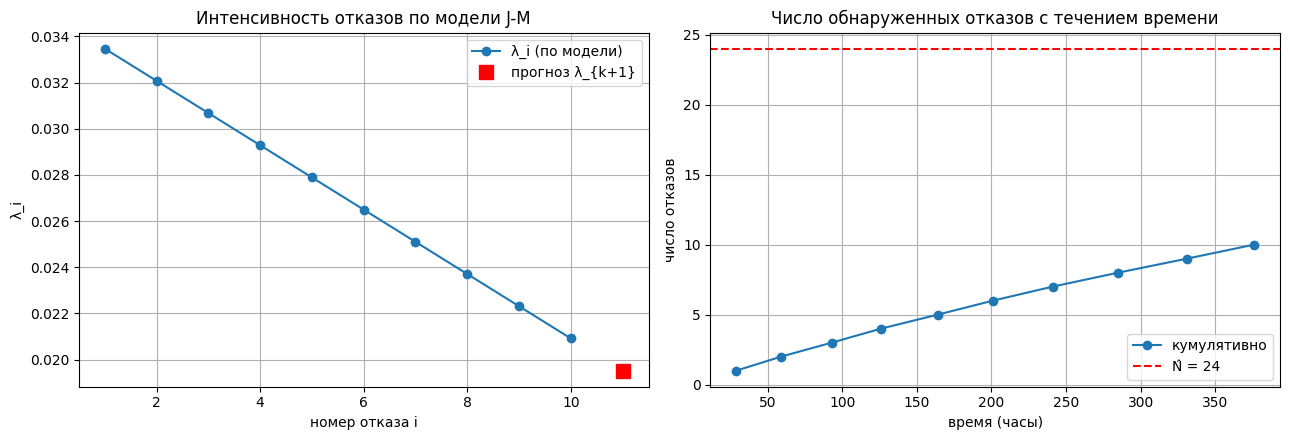

In [6]:
# Графики: λ_i (исторически и прогноз) и кумулятивное число отказов
lam_hist = CD * (N_hat - i + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(i, lam_hist, 'o-', label='λ_i (по модели)')
ax[0].plot(k+1, lam_next, 'rs', ms=10, label=f'прогноз λ_{{k+1}}')
ax[0].set_title('Интенсивность отказов по модели J-M')
ax[0].set_xlabel('номер отказа i'); ax[0].set_ylabel('λ_i')
ax[0].legend()

cum_t = np.cumsum(T)
ax[1].plot(cum_t, np.arange(1, k+1), 'o-', label='кумулятивно')
ax[1].set_title('Число обнаруженных отказов с течением времени')
ax[1].set_xlabel('время (часы)'); ax[1].set_ylabel('число отказов')
ax[1].axhline(N_hat, color='r', ls='--', label=f'N̂ = {N_hat}')
ax[1].legend()
plt.tight_layout(); plt.show()


## Часть 2. Модель Ла Падула

**Идея.** Тестирование идёт этапами; на $i$-м этапе из $S_i$ тестов случились $m_i$ отказов. Эмпирическая надёжность этапа: $R_i = (S_i - m_i)/S_i$. Модель утверждает, что с ростом $i$ надёжность стремится к пределу:
$$R(i) = R(\infty) - \frac{A}{i}.$$

**Зачем это нужно.** Получить две вещи: предельную надёжность $R(\infty)$ и скорость приближения к ней (параметр $A$). По методичке принимаем $S_i = 100$ (число тестов на этапе фиксировано).

Минимизация суммы квадратов отклонений сводится к **линейной регрессии**:
$$R_i = R(\infty) + A\cdot\Big(-\frac{1}{i}\Big).$$

То есть $R_i$ линейно по $-1/i$, наклон даёт $A$, свободный член — $R(\infty)$.


In [7]:
S = 100                # число тестов на каждом этапе
R_i = 1 - m/S          # эмпирическая надёжность каждого этапа
ii = np.arange(1, len(m)+1)
x = -1.0/ii
y = R_i
# Линейная регрессия y = b0 + b1*x
b1, b0 = np.polyfit(x, y, 1)
A_hat = b1
R_inf = b0
print(f'R(∞) ≈ {R_inf:.4f}')
print(f'A    ≈ {A_hat:.4f}')
print(f'Эмпирические R_i: {np.round(R_i,3)}')


R(∞) ≈ 0.8185
A    ≈ -0.0837
Эмпирические R_i: [0.98 0.77 0.78 0.73 0.8  0.84 0.77 0.96 0.86 0.94]


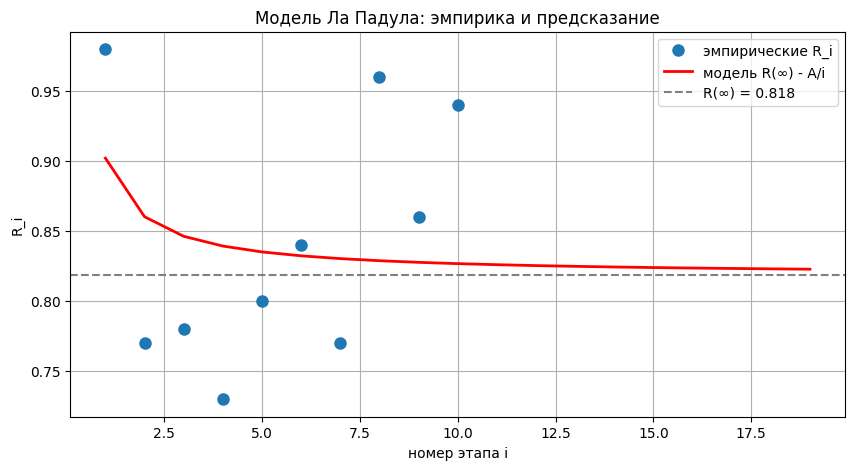

In [8]:
# Прогноз: надёжность на следующих этапах
i_future = np.arange(1, len(m)+10)
R_model = R_inf - A_hat / i_future

plt.figure()
plt.plot(ii, R_i, 'o', ms=8, label='эмпирические R_i')
plt.plot(i_future, R_model, 'r-', lw=2, label=f'модель R(∞) - A/i')
plt.axhline(R_inf, color='gray', ls='--', label=f'R(∞) = {R_inf:.3f}')
plt.title('Модель Ла Падула: эмпирика и предсказание')
plt.xlabel('номер этапа i'); plt.ylabel('R_i')
plt.legend(); plt.show()


## Выводы

1. **Модель Джелински–Моранды** оценила первоначальное число ошибок $\hat N$ методом подбора, что позволило спрогнозировать интенсивность и среднее время до следующего отказа. Чем больше отказов уже найдено и устранено, тем меньше $\lambda$ для следующего — это видно на левом графике.

2. **Модель Ла Падула** даёт предельную надёжность $R(\infty)$. Это полезный практический показатель: «насколько хорош ПО будет после длительного тестирования». Параметр $A$ показывает, насколько быстро мы к этому пределу приближаемся.

3. **Две модели — два взгляда.** J–M считает явное «число оставшихся ошибок», Ла Падула просто экстраполирует надёжность. На реальном проекте обычно используют обе: J–M даёт прогноз времени до следующего бага, Ла Падула — предельную надёжность.
